<a href="https://colab.research.google.com/github/jesobczyk/NustecSchool2026/blob/main/L2_Orbitals/L2_eep_Orbitals_SpectralFunction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# From the local Fermi gas to shell-model: (e,e′p) 
### Lecture 2 interlude — "measuring" the spectral function

| Panel | Knobs | Question |
|---|---|---|
| **A** Design a measurement | where to aim (missing momentum, missing energy), electron angle | Where are the protons of argon, and what does it cost to measure each region? |
| **B** The well and the data | depth of the well for each shell (both start at the same value) | Are the orbitals at the right energies and momenta? |
| **C** Count the protons | spectroscopic factors | How many protons are in the shells? |
| **D** Close the loop | (from B and C) | Does the spectral function give back the inclusive (e,e′) peak? |
| **E** Rosenbluth-separated responses | data set | Where exactly does the strength go missing: longitudinal or transverse? |

Data: `data/dutta_*.txt` (JLab E91-013, exact marker positions from the vector PDF), `data/mougey_*.txt` (Saclay 1976, digitised from the scanned figures, ≈5 %), `data/12C.dat` (QES archive),
`data/LT/` (separated responses: Jourdan NPA 603 (1996) world data for ¹²C and ⁴⁰Ca; Williamson et al. PRC 56 (1997) 3152; Meziani et al. PRL 52 (1984) 2130).

> Sliders missing? Run `demo.USE_WIDGETS = False` after the import cell: every panel is then shown as a set of static figures.
>
> All the physics code is in `qe_l2.py` next to this notebook; open it if you want to see how a panel is computed.

In [1]:
#@title ▶ Run this cell first (sets up the notebook on Google Colab; does nothing on your own computer)
import os, sys
if 'google.colab' in sys.modules:
    if not os.path.isdir('/content/NustecSchool2026'):
        !git clone -q https://github.com/jesobczyk/NustecSchool2026.git /content/NustecSchool2026
    %cd /content/NustecSchool2026/L2_Orbitals
    from google.colab import output
    output.enable_custom_widget_manager()
%matplotlib inline

### Running on your own computer (skip this on Google Colab)

The notebook needs `numpy`, `scipy`, `matplotlib` and `ipywidgets` (the package that draws the sliders). Install them once, in a terminal:

```bash
pip install numpy scipy matplotlib ipywidgets jupyterlab
```

or, if you use conda:

```bash
conda install -c conda-forge numpy scipy matplotlib ipywidgets jupyterlab
```

From the repository folder, `pip install -r requirements.txt` does the same. You can also install from inside the notebook by running `%pip install ipywidgets` in a cell, and then restarting the kernel.

Then start Jupyter with `jupyter lab` and open this notebook.

- **JupyterLab 3 or newer, Notebook 7 or newer, and VS Code** show the sliders as soon as `ipywidgets` is installed in the same Python environment as the kernel.
- **Classic Jupyter Notebook (older than version 7):** also run `jupyter nbextension enable --py widgetsnbextension`, then restart Jupyter.
- If you see *"Error displaying widget"* or no sliders: restart the kernel (and the Jupyter server). As a last resort, uncomment `demo.USE_WIDGETS = False` in the next cell to get static versions of all panels.

In [2]:
import qe_l2 as demo          # all the physics lives in qe_l2.py
# demo.USE_WIDGETS = False   # uncomment if the sliders do not appear

## A. Design a spectral-function measurement

**What (e,e′p) measures.** An electron of energy $E_e$ scatters to $(E_{e'}, \theta_e)$ and a proton is detected in coincidence with momentum $\mathbf p'$.
The virtual photon carries $\omega = E_e - E_{e'}$ and $\mathbf q = \mathbf k - \mathbf k'$. Two quantities follow from conservation laws alone,

$$\mathbf p_m = \mathbf q - \mathbf p' \qquad\qquad E_m = \omega - T_{p'} - T_{A-1}\,,$$

the **missing momentum** and the **missing energy**. If the photon is absorbed by one proton that leaves without further interaction (the plane-wave impulse
approximation), $p_m$ is the momentum the proton had inside the nucleus and $E_m$ the energy it cost to remove it, and the cross section factorises,

$$\frac{d^6\sigma}{dE_{e'}\,d\Omega_{e'}\,dE_{p'}\,d\Omega_{p'}} = K\;\sigma_{ep}\;P(p_m, E_m)\,,$$

with $K$ a phase-space factor, $\sigma_{ep}$ the electron–proton cross section (off-shell, known) and $P(p,E)$ the **spectral function**. Dividing the measured
cross section by $K\sigma_{ep}$ *is* a measurement of $P$. In reality the outgoing proton can rescatter on its way out of the nucleus (final-state interactions).
This does not change the number of events, but moves them to other values of $p_m$ and $E_m$. In this panel we assume there are no final-state interactions
and do not include this smearing.

**Parallel kinematics.** Spectral-function experiments put the proton spectrometer along $\mathbf q$. Then the two interference responses of (e,e′p) vanish, the
factorisation survives final-state interactions best, and two-body currents are suppressed.

**The argon experiment at JLab (proposal PR12-14-012, arXiv:1406.4080).** 2.2 GeV beam on a gas argon target,
nine days of beam, and twelve settings — ten in parallel kinematics stepping the missing momentum from 20 to 380 MeV/c, and two "anti-parallel" ones
(proton slower than $\mathbf q$, negative $p_m$) to test the treatment of final-state interactions. All have $E'$ = 1.717 GeV and $p'$ = 1.000 GeV/c, so
$E_m$ ≈ 50 MeV:

| setting | E′ [GeV] | θ_e | T_p [MeV] (p′ [GeV/c]) | θ_p | \|q\| [MeV/c] | p_m [MeV/c] | E_m [MeV] |
|---|---|---|---|---|---|---|---|
| 01 | 1.717 | 25.3° | 433 (1.000) | −48.6° | 980 | 20 | ≈ 50 |
| 02 | 1.717 | 23.9° | 433 (1.000) | −47.8° | 940 | 60 | ≈ 50 |
| 03 | 1.717 | 22.5° | 433 (1.000) | −47.0° | 900 | 100 | ≈ 50 |
| 04 | 1.717 | 21.1° | 433 (1.000) | −45.9° | 860 | 140 | ≈ 50 |
| 05 | 1.717 | 19.6° | 433 (1.000) | −44.7° | 820 | 180 | ≈ 50 |
| 06 | 1.717 | 18.1° | 433 (1.000) | −43.2° | 780 | 220 | ≈ 50 |
| 07 | 1.717 | 16.6° | 433 (1.000) | −41.4° | 740 | 260 | ≈ 50 |
| 08 | 1.717 | 15.0° | 433 (1.000) | −39.3° | 700 | 300 | ≈ 50 |
| 09 | 1.717 | 13.3° | 433 (1.000) | −36.7° | 660 | 340 | ≈ 50 |
| 10 | 1.717 | 11.5° | 433 (1.000) | −33.4° | 620 | 380 | ≈ 50 |
| 11 | 1.717 | 29.8° | 433 (1.000) | −50.2° | 1110 | -110 | ≈ 50 |
| 12 | 1.717 | 34.4° | 433 (1.000) | −51.1° | 1247 | -247 | ≈ 50 |

The experiment (E12-14-012) took **five** settings, all in parallel kinematics:

| setting | E′ [GeV] | θ_e | T_p [MeV] (p′ [GeV/c]) | θ_p | Q² [GeV²] | p_m [MeV/c] | E_m [MeV] |
|---|---|---|---|---|---|---|---|
| 1 | 1.777 | 21.5° | 372 (0.915) | −50.0° | 0.55 | 50 | 73 |
| 2 | 1.716 | 20.0° | 455 (1.030) | −44.0° | 0.46 | 184 | 50 |
| 3 | 1.799 | 17.5° | 372 (0.915) | −47.0° | 0.37 | 174 | 50 |
| 4 | 1.799 | 15.5° | 372 (0.915) | −44.5° | 0.29 | 230 | 50 |
| 5 | 1.716 | 15.5° | 455 (1.030) | −39.0° | 0.28 | 300 | 50 |

Together they cover $15 \lesssim p_m \lesssim 300$ MeV/c and $12 \lesssim E_m \lesssim 80$ MeV. The fitted spectral function (Jiang *et al.*, PRD 107, 012005 (2023))
has 13.2 protons in the shells and 3.8 in correlated pairs.

The sketch shows the geometry with the electron of setting 2 and the proton turned 10° away from $\mathbf q$, so that the missing-momentum triangle is visible;
in parallel kinematics the triangle collapses onto a line and $p_m = |\mathbf p'| - |\mathbf q|$.

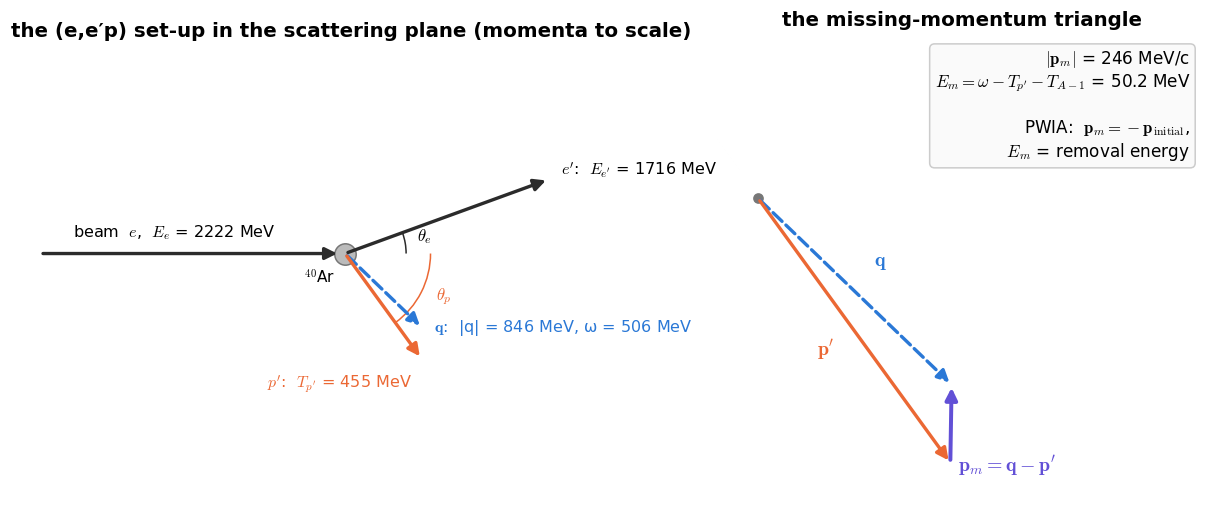

In [3]:
demo.eep_sketch(E_e=2222, E_ep=1716, th_e=20.0, T_p=455, th_p=54.0)

**The panel.**  The map shows the spectral function of argon $4\pi p^2 P(p,E)$ on a linear scale:
the **1d and 2s shells** sit around the separation energy ($E_m \approx$ 12–18 MeV), the **1p shell** at $E_m \approx 30$ MeV, the deep **1s shell** is a broad,
faint band around 50 MeV, and protons in **correlated pairs** spread to high $p_m$ and $E_m$.
The energies, widths and numbers of protons of the shells are those fitted to the JLab data (Jiang *et al.* 2023); the momentum dependence of each shell is a
Woods–Saxon orbital. The plot on the right shows the same model as a missing-energy spectrum, shell by shell.

Choose where to aim (missing momentum and missing energy) and the electron angle. The panel finds the electron energy and the proton momentum that put
the centre of your setting there, with the proton along $\mathbf q$, and simulates the two spectrometers (±4.5 % in momentum, about 7 msr each), without final-state interactions.
The blue area is what one setting sees (the region covered by the two spectrometers). The five boxes cover $0 < E_m < 80$ MeV in steps of 100 MeV/c in missing momentum; the numbers give the count rate in each box (counts per hour) next to the number of protons the model puts in that box.
Is the box with the most protons always the one with the most counts? (The rate depends on where you aim: one setting covers only a slice of each box.)
Positive missing momentum means the proton is faster than $\mathbf q$ (the JLab choice), negative that it is slower.

**Try this.**
1. Aim at $p_m$=50 MeV/c, then at 150 MeV/c (missing energy 50 MeV). Which boxes collect counts, and how many per hour? 
2. Step the missing momentum up box by box (150, 250, 350, 450 MeV/c). How fast does the rate fall? How long would 10 000 counts (1 % statistics) take in the last box? Try both signs of the missing momentum and different electron angles.
3. Try some of the proposed settings: aim at $E_m$ = 50 MeV and $p_m$ = 20, 140, 300, 380 MeV/c, and at −110 and −247 MeV/c. Which of them would you keep if the beam time were cut? Compare with the five settings that were actually run.

*How realistic are the rates?* They are an upper estimate: luminosity $10^{36}$ cm⁻² s⁻¹ per argon nucleus (15 μA on the 25 cm, 1.4 g/cm² argon gas cell of the experiment gives about 2 × 10³⁶),
plane-wave impulse approximation (no final-state interactions, which remove about 40–50 % of the protons), and no efficiencies, dead time or analysis cuts.
For comparison, E12-14-012 collected 29.6 hours of argon data in its first setting and kept about 44 000 events after all cuts (Gu *et al.*, PRC 103, 034604 (2021)).

In [4]:
demo.show_A()

Output()

## B. The well and the data

**The model.** Each proton moves in the average potential of all the others. The standard
parametrisation is the Woods–Saxon well,

$$V(r) = -\,\frac{V_0}{1+e^{(r-R)/a}} \;+\; V_{so}\Big(\frac{\hbar}{m_\pi c}\Big)^2 \frac{1}{r}\frac{df}{dr}\;\boldsymbol\ell\cdot\mathbf s \;+\; V_C(r)\,,
\qquad R = r_0 A^{1/3}.$$

Solving the radial Schrödinger equation gives the orbitals; for carbon the protons fill $1s_{1/2}$ (2) and $1p_{3/2}$ (4). In the independent-particle picture
the removal energy of a proton from shell $\alpha$ is $E_m = -\varepsilon_\alpha$, and its momentum distribution is the Fourier–Bessel transform of the
orbital, $n_\alpha(p) \propto |\int u_\alpha(r)\, j_\ell(pr)\, r\,dr|^2$.

**The parameters.** Each is pinned down by a measurement:

| parameter | fixed by |
|---|---|
| radius $r_0$ = 1.32 fm, surface $a$ = 0.55 fm | elastic electron scattering: the charge density and radius (2.47 fm) of carbon |
| spin–orbit $V_{so}$ = 9 MeV | the $p_{3/2}$–$p_{1/2}$ splitting in the neighbouring nuclei |
| depth $V_0$ | the removal energies measured in (e,e′p) |

As in the lecture, we start with **one depth for both shells**, $V_0$ = 57 MeV. Mougey *et al.* (Saclay 1976) instead adjusted the depth separately for each
shell (55 and 66 MeV); the two knobs below let you do the same. Everything else stays at its measured value.

**What the plots show.** Left: the removal energy of each shell, model (line) against Mougey's (e,e′p) measurement (dashed line; the band is the width of the peak).
Middle and right: the momentum distribution $n(p)$ of each **full** shell (4 and 2 protons, no spectroscopic factors) against the (e,e′p) data with the
final-state interactions removed. The measured distributions are distorted: the outgoing proton can rescatter or be absorbed. Each experiment corrects for
this with its own factor, and we divide by it — Dutta *et al.* (JLab 2003) by the transparency $T$ = 0.60, Mougey *et al.* by the distortion factors
$\eta$ = 0.66 (1p) and 0.52 (1s) from the distorted-wave impulse approximation.

**Try this.**
1. With one depth, which shell sits at the measured energy, and which does not? Give the 1s shell its own depth: which value puts it at 38 MeV? What happens to its $n(p)$?
2. Shapes: does the model put the protons at the right momenta? Where do the two shells differ, and why does the 1p vanish at $p = 0$ while the 1s peaks there?

In [5]:
demo.show_B()

Output()

## C. Build the spectral function and compare with the data

**From orbitals to a spectral function.** In the independent-particle model (IPM) removing a nucleon from shell $\alpha$ leaves the residual nucleus in one
definite state, so the spectral function is a sum of stripes in the $(p,E)$ plane:

$$P(p,E) = \sum_\alpha S_\alpha\,(2j_\alpha+1)\; n_\alpha(p)\; L_\alpha(E)\,,\qquad \int 4\pi p^2\,dp\,dE\;P(p,E) = Z\ \text{ if all } S_\alpha = 1.$$

$L_\alpha(E)$ is a line at $E = -\varepsilon_\alpha$; for the 1p hole of carbon it is sharp (the residual $^{11}$B is in its ground state), for the 1s hole it is
≈ 20 MeV wide because a hole that deep decays into many states of $^{11}$B — the width is the one piece of many-body physics the IPM admits. The factors
$S_\alpha$ are the **spectroscopic factors**: the probability that the state reached by removing a nucleon from orbital $\alpha$ is actually the single-hole state.
In a pure mean field $S_\alpha = 1$.

**Count the protons.** The bottom row shows $4\pi p^2 n(p)$: the **area under the curve is the number of protons**. The model is the orbital times its
spectroscopic factor (solid; dotted: the full shell), the data are those of Panel B with the final-state interactions removed (Dutta ÷ 0.60, Mougey ÷ $\eta$).
The legends and the box give the number of protons below 300 MeV/c, the range the data cover.

**Your task.** Tune the two spectroscopic factors until the model holds as many protons as the data, first for Dutta, then for Mougey.
Then look at the missing-energy projection at the top right: does it agree as well?

**Try this.**
1. Which spectroscopic factors do you find for the 1p and the 1s shell? How many of the 6 protons are in the orbitals?
2. Once the areas agree, compare the shapes of the 1p distribution: where is the model too high, where too low?
3. The two experiments, both corrected, do not give the same number of protons. What does that tell you about the uncertainty of a spectroscopic factor?

*Normalisation, for the curious.* Dutta's transparency $T$ = 0.60 (their Table III) is the probability that the proton leaves the nucleus without
rescattering, computed with a Glauber model; Mougey's $\eta$ is the ratio of the distorted-wave to the plane-wave cross section for each shell. Both are model
calculations, so the corrected numbers carry their uncertainty. The missing-energy spectrum (Dutta Fig. 9, published with a different normalisation) is
scaled so that its two windows hold the same protons as Fig. 10, then divided by $T$.

In [6]:
demo.show_C()

Output()

## D. Close the loop: the inclusive peak from the spectral function

**The formula.** In the impulse approximation the inclusive response is the single-nucleon response summed over every nucleon the nucleus can offer, each
with its own momentum and removal energy:

$$R_{L,T}(q,\omega) = \int d^3p\,dE\; P(p,E)\; R^{(1)}_{L,T}(p, q, \omega - E)\;\delta\big(\omega - E - E_{p+q} + E_p\big)\,,$$

where the nucleon tensor is the free one of Lecture 1 evaluated with the energy transfer $\omega - E$ (the photon first pays the removal energy). With full occupation (S = 1) the response is about 20 % too
high — but (e,e′p) just told us the orbitals hold only about 70 % of the protons (4.2 of 6). The spectroscopic factors are the ones you set in Panel C (the panel listens to
those sliders, and to the well of Panel B): put in the values that fit the (e,e′p) data and the inclusive peak is about 20 % too low. The strength that is not in
the orbitals must still contribute to the inclusive cross section, somewhere else in $(p, E)$. 

In [7]:
demo.show_D()

Output()

## E. Rosenbluth-separated responses: where exactly does the strength go missing?

**Two responses, two stories.** The inclusive cross section of Lecture 1 is $\sigma_{\rm Mott}\,[\,v_L R_L + v_T R_T\,]$: one number per $(q,\omega)$ for a
combination of the charge response $R_L$ and the current response $R_T$. Measuring at several beam energies and angles that reach the same $(q,\omega)$ with
different $v_L/v_T$ — the Rosenbluth separation — gives the two responses separately, at the price of error bars that are typically 10 % after the
separation. The longitudinal response is the cleaner probe of nucleon *density*: it is dominated by the charge of the proton and is nearly blind to
two-body currents. The transverse one carries the magnetisation current and everything that involves pions and $\Delta$s.

**What the data say.** The panel shows the world data for $^{12}$C (Jourdan 1996) at three fixed values of $q$, against the Fermi gas with all protons and the orbitals with the spectroscopic factors of Panel C (the same calculation as Panel D, now kept
separate in L and T). Look at the **longitudinal** response first: the depleted orbitals describe it, while the data lie about 30 % below the Fermi gas with six protons
— this is the "longitudinal quenching" that puzzled people in the 1980s, and it is to a large extent the same missing strength that (e,e′p) sees. Then the
**transverse** one: the same depleted orbitals fall short, by about 10 % at $q$ = 300 MeV and up to a factor 1.7 at 570 MeV; at $q$ = 570 MeV the data exceed even the six-proton
Fermi gas. So the missing third of the protons is not simply absent; it reappears in $R_T$, with an excess on top. No single occupation number and no mean field
can do that — both multiply $R_L$ and $R_T$ alike. What distinguishes L from T is the current operator, and the transverse excess is the fingerprint of two-body
currents, where the photon couples to a pair of nucleons. That, together with where the correlated nucleons went, is Lecture 3.

The ratios in the titles are integrals over the quasielastic peak region only (where the orbital response is above 20 % of its maximum).

In [8]:
demo.show_E()

Output()

## What the orbitals give and what they do not
The shells are there: two peaks in $E_m$, the right momentum distributions, the asymmetric inclusive peak, and the longitudinal response. But with full occupation the model overshoots everything,
and the data are described only with spectroscopic factors of about 0.55–0.8. About a third of the protons are not in the orbitals at the energies and momenta where the
orbitals put them — and the transverse response shows that they still interact. Lecture 3 is about where they are: correlations, the high-momentum tail already seen in the scaling plot, two-body currents, and the methods that compute it.

## Answers: Panels B and C

### Panel B
1. **Energies with one depth.** With $V_0$ = 57 MeV the 1p shell is at 16.1 MeV, close to the measured 17.5 MeV, but the 1s shell is at 31.6 MeV instead of
   38.1 MeV: it is not bound enough. Giving the 1s shell its own depth of about 65 MeV puts it at 38 MeV (Mougey used 66 MeV; for the 1p, 59 MeV would match exactly).
   Its $n(p)$ hardly changes: a deeper well squeezes the orbital a little, so $n(0)$ drops by about 10 % and the distribution gets slightly wider in $p$.
   The energy and the shape of an orbital are almost independent knobs.
2. **Shapes.** Yes: the model 1p peaks at about 105 MeV/c, the data at 100–105 MeV/c, and both shells fall off by about 250 MeV/c, as in the data.
   The 1p distribution vanishes at $p = 0$ because the orbital has $\ell = 1$: its Fourier–Bessel transform contains $j_1(pr)$, which is zero at $p = 0$
   (an orbital with angular momentum cannot have zero momentum). The 1s orbital has $\ell = 0$ and $j_0(0) = 1$, so it peaks at $p = 0$.

### Panel C
1. **Spectroscopic factors.** Matching the areas below 300 MeV/c:
   - with Dutta ÷ 0.60: $S$(1p) ≈ 0.77 and $S$(1s) ≈ 0.55, so $4 \times 0.77 + 2 \times 0.55$ ≈ 4.2 of the 6 protons are in the orbitals;
   - with Mougey ÷ $\eta$: $S$(1p) ≈ 0.62 and $S$(1s) ≈ 0.48, so about 3.4 of 6.

   Either way, 1.8 to 2.6 protons are missing from the shells.
2. **Shape of the 1p distribution.** With $S$(1p) = 0.77 the model is about 10–15 % too low at the peak (100–140 MeV/c) and 15–25 % too high above
   200 MeV/c: the model orbital is wider in momentum, that is, slightly too compact in coordinate space. Part of the difference comes from the
   final-state interactions, which reshape the measured distribution and not only reduce it, and part from the window 10–25 MeV, which also
   collects the low-energy tail of the broad 1s peak.
3. **Two experiments.** Both data sets are corrected for final-state interactions with a model (a Glauber transparency for Dutta, distorted-wave
   factors for Mougey), and they use different windows in $E_m$ (10–25 against 15–21.5 MeV for the p-shell) and different kinematics. The resulting
   numbers of protons differ by about 20 % for the 1p and 10 % for the 1s. A spectroscopic factor is therefore not a direct observable: it carries the
   uncertainty of the reaction model, here of order 10–20 %.
